In [27]:
# Step 1. Import Libraries and load required files

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

PROJECT_ROOT = Path.cwd().parent
DATA_PROCESSED = PROJECT_ROOT / "data_processed"
OUTPUTS = PROJECT_ROOT / "outputs"

df = pd.read_csv(DATA_PROCESSED / "stroke_risk_panel_clean.csv")
coef_table = pd.read_csv(DATA_PROCESSED / "model_2_coefficients.csv")
std_coef_table = pd.read_csv(DATA_PROCESSED / "model_2_standardized_coefficients.csv")
model_compare_ols = pd.read_csv(DATA_PROCESSED / "model_compare_ols.csv")
vif_df = pd.read_csv(DATA_PROCESSED / "model_vif.csv")
ridge_lasso_metrics = pd.read_csv(DATA_PROCESSED / "ridge_lasso_metrics.csv")

print("Files loaded successfully.")

Files loaded successfully.


In [29]:
# Step 2. Quick Review of inputs

print("Dataset shape:", df.shape)
print("\nYears:", sorted(df["Year"].unique()))
print("\nPHUs:", df["PHU"].nunique())

print("\nModel comparison")
display(model_compare_ols)

print("\nVIF table")
display(vif_df)

print("\nCoefficient table")
display(coef_table)

print("\nStandardized coefficient table")
display(std_coef_table)

print("\nRidge/Lasso metrics")
display(ridge_lasso_metrics)

Dataset shape: (44, 7)

Years: [np.int64(2016), np.int64(2017)]

PHUs: 22

Model comparison


,Model,R_squared,Adj_R_squared,AIC,BIC
0,Baseline OLS,0.431830,0.373557,377.239191,386.160139
1,OLS + Year Effect,0.434985,0.360640,378.994243,389.699381



VIF table


,variable,VIF
0,const,1247.605304
1,smoking_rate,3.357781
2,no_pa_minutes_rate,1.428031
3,low_fv_rate,1.441991
4,heavy_drinking_rate,3.314954



Coefficient table


,variable,coefficient,p_value,conf_low,conf_high
0,Intercept,108.314365,0.235190,-73.469644,290.098374
1,C(Year)[T.2017],2.340909,0.647724,-7.948089,12.629907
2,smoking_rate,3.437963,0.002435,1.294895,5.581031
3,no_pa_minutes_rate,-1.662536,0.086199,-3.573201,0.248129
4,low_fv_rate,0.438415,0.713532,-1.961132,2.837961
5,heavy_drinking_rate,-0.830709,0.249194,-2.267758,0.606339



Standardized coefficient table


,variable,standardized_coefficient,p_value
0,Intercept,-0.055520,0.746453
1,C(Year)[T.2017],0.111041,0.647724
2,smoking_rate,0.725646,0.002435
3,no_pa_minutes_rate,-0.256678,0.086199
4,low_fv_rate,0.054159,0.713532
5,heavy_drinking_rate,-0.259806,0.249194



Ridge/Lasso metrics


,Model,R_squared,RMSE,MAE
0,Ridge,0.41634,11.895525,10.664397
1,Lasso,0.43108,11.744361,10.611164


In [30]:
# Step 3. Identify statistically significant variables

significant_vars = coef_table[
    (coef_table["p_value"] < 0.05) &
    (~coef_table["variable"].isin(["Intercept"]))
].copy()

significant_vars

,variable,coefficient,p_value,conf_low,conf_high
2,smoking_rate,3.437963,0.002435,1.294895,5.581031


In [31]:
# Step 4. Identify strongest standardized predictors

std_ranked = std_coef_table[
    ~std_coef_table["variable"].isin(["Intercept"])
].copy()

std_ranked["abs_standardized_coefficient"] = std_ranked["standardized_coefficient"].abs()
std_ranked = std_ranked.sort_values(by="abs_standardized_coefficient", ascending=False)

std_ranked

,variable,standardized_coefficient,p_value,abs_standardized_coefficient
2,smoking_rate,0.725646,0.002435,0.725646
5,heavy_drinking_rate,-0.259806,0.249194,0.259806
3,no_pa_minutes_rate,-0.256678,0.086199,0.256678
1,C(Year)[T.2017],0.111041,0.647724,0.111041
4,low_fv_rate,0.054159,0.713532,0.054159


In [32]:
# Step 5. Create key findings Table

key_findings = pd.DataFrame({
    "Finding": [
        "Main regression model",
        "Model R-squared",
        "Best predictive regularized model",
        "Statistically significant predictor",
        "Strongest standardized predictor",
        "Multicollinearity status"
    ],
    "Value": [
        "OLS with Year Effect",
        round(model_compare_ols.loc[model_compare_ols["Model"] == "OLS + Year Effect", "R_squared"].iloc[0], 4),
        ridge_lasso_metrics.sort_values(by="R_squared", ascending=False)["Model"].iloc[0],
        ", ".join(significant_vars["variable"].tolist()) if len(significant_vars) > 0 else "None",
        std_ranked["variable"].iloc[0],
        "Acceptable, all predictor VIF values below 5"
    ]
})

key_findings

,Finding,Value
0,Main regression model,OLS with Year Effect
1,Model R-squared,0.435
2,Best predictive regularized model,Lasso
3,Statistically significant predictor,smoking_rate
4,Strongest standardized predictor,smoking_rate
5,Multicollinearity status,"Acceptable, all predictor VIF values below 5"


In [33]:
# Step 6. Save key findings Table

key_findings.to_csv(DATA_PROCESSED / "final_key_findings.csv", index=False)
print("Saved final_key_findings.csv")

Saved final_key_findings.csv


In [34]:
# Step 7. Create final recommendation logic table

recommendations_table = pd.DataFrame({
    "Priority": [1, 2, 3, 4],
    "Risk Factor": [
        "Smoking",
        "Physical inactivity",
        "Heavy drinking",
        "Poor fruit and vegetable consumption"
    ],
    "Evidence from model": [
        "Strong positive association and statistically significant",
        "Moderate association but not statistically significant at 5% level",
        "Weak to moderate association, not statistically significant",
        "Weak association in current model"
    ],
    "Recommended action": [
        "Prioritize smoking cessation interventions, outreach, and prevention campaigns",
        "Expand physical activity promotion, especially community and workplace programs",
        "Continue monitoring alcohol-related risk and target high-risk PHUs with prevention messaging",
        "Support nutrition education and healthy food access initiatives"
    ],
    "Priority level": [
        "High",
        "Medium",
        "Medium",
        "Medium to Low"
    ]
})

recommendations_table

,Priority,Risk Factor,Evidence from model,Recommended action,Priority level
0,1,Smoking,Strong positive association and statistically ...,"Prioritize smoking cessation interventions, ou...",High
1,2,Physical inactivity,Moderate association but not statistically sig...,"Expand physical activity promotion, especially...",Medium
2,3,Heavy drinking,"Weak to moderate association, not statisticall...",Continue monitoring alcohol-related risk and t...,Medium
3,4,Poor fruit and vegetable consumption,Weak association in current model,Support nutrition education and healthy food a...,Medium to Low


In [35]:
# Step 8. Save recommendation Table

recommendations_table.to_csv(DATA_PROCESSED / "final_recommendations_table.csv", index=False)
print("Saved final_recommendations_table.csv")

Saved final_recommendations_table.csv


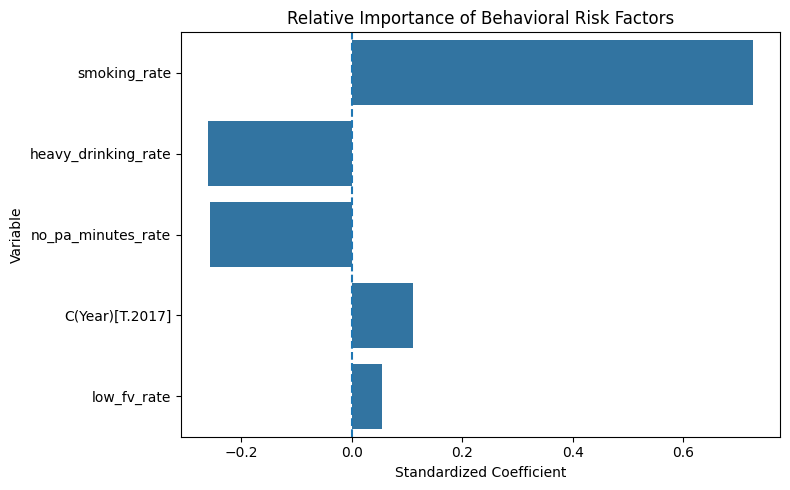

In [36]:
# Step 9. Create a ranked coefficient chart

plot_df = std_ranked.copy()

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x="standardized_coefficient", y="variable")
plt.axvline(0, linestyle="--")
plt.title("Relative Importance of Behavioral Risk Factors")
plt.xlabel("Standardized Coefficient")
plt.ylabel("Variable")
plt.tight_layout()
plt.savefig(OUTPUTS / "final_ranked_risk_factors.png")
plt.show()

In [37]:
# Step 10. Create top PHUs based on average stroke hospitalization

top_phus = (
    df.groupby("PHU")["stroke_hosp_rate"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_phus

,PHU,stroke_hosp_rate
0,Northwestern Health Unit,178.15
1,Southwestern Public Health,150.65
2,Huron Perth Public Health,145.45
3,Chatham-Kent Public Health,142.85
4,Thunder Bay District Health Unit,142.15
5,City of Hamilton Public Health Services,133.50
6,Renfrew County and District Health Unit,133.05
7,Algoma Public Health,129.45
8,Wellington-Dufferin-Guelph Public Health,128.80
9,Lambton Public Health,124.30


In [38]:
# Step 11. Save top PHUs

top_phus.to_csv(DATA_PROCESSED / "final_top10_phus.csv", index=False)
print("Saved final_top10_phus.csv")

Saved final_top10_phus.csv


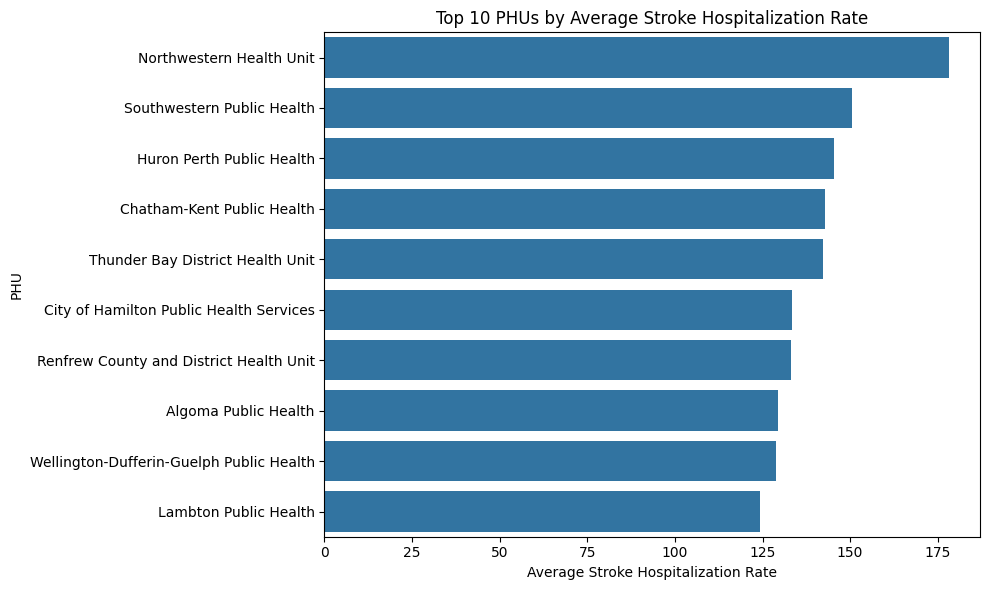

In [39]:
# Step 12. Plot top PHUs

plt.figure(figsize=(10, 6))
sns.barplot(data=top_phus, x="stroke_hosp_rate", y="PHU")
plt.title("Top 10 PHUs by Average Stroke Hospitalization Rate")
plt.xlabel("Average Stroke Hospitalization Rate")
plt.ylabel("PHU")
plt.tight_layout()
plt.savefig(OUTPUTS / "final_top10_phus_chart.png")
plt.show()

In [40]:
# Step 13. Create PHUs risk summary profile

risk_cols = [
    "smoking_rate",
    "no_pa_minutes_rate",
    "low_fv_rate",
    "heavy_drinking_rate"
]

phu_profile = df.groupby("PHU")[["stroke_hosp_rate"] + risk_cols].mean().reset_index()
phu_profile.head()

,PHU,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
0,Algoma Public Health,129.45,26.2,19.0,73.2,55.1
1,Chatham-Kent Public Health,142.85,19.0,20.6,72.7,49.5
2,City of Hamilton Public Health Services,133.50,15.3,17.3,75.3,43.9
3,Durham Region Health Department,109.50,14.6,19.7,71.6,51.0
4,Halton Region Public Health,88.85,11.2,22.4,72.2,49.5


In [41]:
# Step 14. Identify highest risk PHUs by smoking

top_smoking_phus = (
    phu_profile[["PHU", "smoking_rate", "stroke_hosp_rate"]]
    .sort_values(by="smoking_rate", ascending=False)
    .head(10)
)

top_smoking_phus

,PHU,smoking_rate,stroke_hosp_rate
0,Algoma Public Health,26.2,129.45
10,Northwestern Health Unit,21.8,178.15
14,Renfrew County and District Health Unit,20.7,133.05
13,Public Health Sudbury & Districts,20.7,117.40
6,Lambton Public Health,20.0,124.30
1,Chatham-Kent Public Health,19.0,142.85
9,North Bay Parry Sound District Health Unit,18.1,121.15
16,Southwestern Public Health,17.5,150.65
17,Thunder Bay District Health Unit,17.3,142.15
15,Simcoe Muskoka District Health Unit,15.9,119.60


In [42]:
# Step 15. Save smoking priority PHUs

top_smoking_phus.to_csv(DATA_PROCESSED / "priority_phus_smoking.csv", index=False)
print("Saved priority_phus_smoking.csv")

Saved priority_phus_smoking.csv


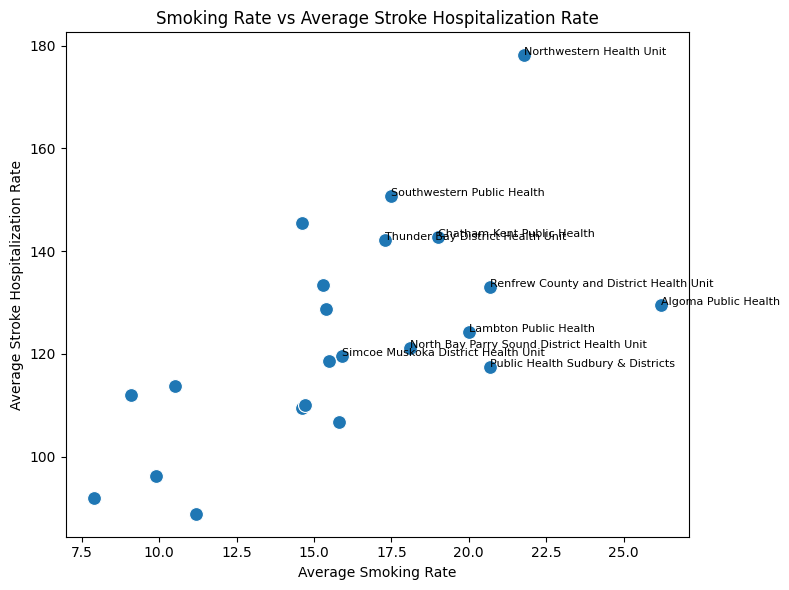

In [43]:
# Step 16. Plot smoking vs stroke hospitallization

plt.figure(figsize=(8, 6))
sns.scatterplot(data=phu_profile, x="smoking_rate", y="stroke_hosp_rate", s=100)

for _, row in top_smoking_phus.iterrows():
    plt.text(row["smoking_rate"], row["stroke_hosp_rate"], row["PHU"], fontsize=8)

plt.title("Smoking Rate vs Average Stroke Hospitalization Rate")
plt.xlabel("Average Smoking Rate")
plt.ylabel("Average Stroke Hospitalization Rate")
plt.tight_layout()
plt.savefig(OUTPUTS / "final_smoking_vs_stroke.png")
plt.show()

In [44]:
# Step 17. Generate summary interpretation text automatically

main_model_r2 = model_compare_ols.loc[
    model_compare_ols["Model"] == "OLS + Year Effect",
    "R_squared"
].iloc[0]

main_predictor = std_ranked["variable"].iloc[0]
main_predictor_coef = coef_table.loc[
    coef_table["variable"] == main_predictor,
    "coefficient"
].iloc[0]

main_predictor_p = coef_table.loc[
    coef_table["variable"] == main_predictor,
    "p_value"
].iloc[0]

summary_text = f"""
Project Summary

This analysis examined the relationship between stroke hospitalization rates and four behavioral risk factors
across Ontario Public Health Units for 2016 and 2017.

The main regression model with year effect explained {main_model_r2:.2%} of the variation in stroke hospitalization rates.

The strongest predictor was {main_predictor}, with an estimated coefficient of {main_predictor_coef:.3f}
and p-value of {main_predictor_p:.4f}.

The results suggest that smoking is the most important behavioral risk factor in this dataset and should
be prioritized in regional prevention strategies.

Other factors, including physical inactivity, poor diet, and heavy drinking, showed weaker or statistically
insignificant relationships in the current sample, but may still be relevant for targeted public health action.

Regularized models were also tested. Lasso slightly outperformed Ridge, indicating that the model is stable
and that the key signal remains concentrated in a small number of predictors.
"""

print(summary_text)


Project Summary

This analysis examined the relationship between stroke hospitalization rates and four behavioral risk factors
across Ontario Public Health Units for 2016 and 2017.

The main regression model with year effect explained 43.50% of the variation in stroke hospitalization rates.

The strongest predictor was smoking_rate, with an estimated coefficient of 3.438
and p-value of 0.0024.

The results suggest that smoking is the most important behavioral risk factor in this dataset and should
be prioritized in regional prevention strategies.

Other factors, including physical inactivity, poor diet, and heavy drinking, showed weaker or statistically
insignificant relationships in the current sample, but may still be relevant for targeted public health action.

Regularized models were also tested. Lasso slightly outperformed Ridge, indicating that the model is stable
and that the key signal remains concentrated in a small number of predictors.



In [45]:
# Step 18. Save summary text to file

with open(OUTPUTS / "final_project_summary.txt", "w") as f:
    f.write(summary_text)

print("Saved final_project_summary.txt")

Saved final_project_summary.txt


In [46]:
# Step 19. Create limitations table

limitations_table = pd.DataFrame({
    "Limitation": [
        "Small sample size",
        "Two-year time window",
        "Ecological design",
        "Forward-filled risk factor assumptions",
        "Potential omitted variables"
    ],
    "Description": [
        "The final dataset includes 44 PHU-year observations, which limits statistical power.",
        "The analysis covers only 2016 and 2017, which may not capture longer-term trends.",
        "Associations are measured at PHU level and do not imply individual-level causation.",
        "Some risk factors were held constant across adjacent years due to data availability.",
        "Other relevant variables such as age distribution, income, or comorbidities were not included."
    ]
})

limitations_table

,Limitation,Description
0,Small sample size,The final dataset includes 44 PHU-year observa...
1,Two-year time window,"The analysis covers only 2016 and 2017, which ..."
2,Ecological design,Associations are measured at PHU level and do ...
3,Forward-filled risk factor assumptions,Some risk factors were held constant across ad...
4,Potential omitted variables,Other relevant variables such as age distribut...


In [47]:
# Step 20. Save limitations Table

limitations_table.to_csv(DATA_PROCESSED / "final_limitations_table.csv", index=False)
print("Saved final_limitations_table.csv")

Saved final_limitations_table.csv


In [48]:
# Step 21. Create future work Table

future_work_table = pd.DataFrame({
    "Future Work": [
        "Expand time horizon",
        "Add demographic covariates",
        "Use panel fixed effects models",
        "Build interactive dashboard",
        "Test classification models"
    ],
    "Description": [
        "Incorporate more years when aligned risk factor data becomes available.",
        "Add socioeconomic and demographic indicators such as marginalization or age composition.",
        "Estimate more advanced longitudinal models controlling for PHU-specific heterogeneity.",
        "Develop a dashboard for regional comparison of risk factors and stroke burden.",
        "Test whether PHUs can be classified into high-risk groups using supervised learning."
    ]
})

future_work_table

,Future Work,Description
0,Expand time horizon,Incorporate more years when aligned risk facto...
1,Add demographic covariates,Add socioeconomic and demographic indicators s...
2,Use panel fixed effects models,Estimate more advanced longitudinal models con...
3,Build interactive dashboard,Develop a dashboard for regional comparison of...
4,Test classification models,Test whether PHUs can be classified into high-...


In [49]:
# Step 22. Save future work Table

future_work_table.to_csv(DATA_PROCESSED / "final_future_work_table.csv", index=False)
print("Saved final_future_work_table.csv")

Saved final_future_work_table.csv


In [50]:
# Step 23. General Final recommendation report table

final_report_table = {
    "Model used": "Multiple Linear Regression with Year Effect, supported by Ridge and Lasso",
    "Main significant predictor": ", ".join(significant_vars["variable"].tolist()) if len(significant_vars) > 0 else "None",
    "Top standardized predictor": std_ranked["variable"].iloc[0],
    "Model R-squared": round(main_model_r2, 4),
    "Best regularized model": ridge_lasso_metrics.sort_values(by="R_squared", ascending=False)["Model"].iloc[0],
    "Top intervention priority": "Smoking reduction",
    "Recommended focus": "Target PHUs with high smoking prevalence and high stroke hospitalization"
}

final_report_df = pd.DataFrame(final_report_table.items(), columns=["Metric", "Value"])
final_report_df

,Metric,Value
0,Model used,"Multiple Linear Regression with Year Effect, s..."
1,Main significant predictor,smoking_rate
2,Top standardized predictor,smoking_rate
3,Model R-squared,0.435
4,Best regularized model,Lasso
5,Top intervention priority,Smoking reduction
6,Recommended focus,Target PHUs with high smoking prevalence and h...


In [51]:
# Step 24. Save final report Table

final_report_df.to_csv(DATA_PROCESSED / "final_report_summary_table.csv", index=False)
print("Saved final_report_summary_table.csv")

Saved final_report_summary_table.csv


In [52]:
# Step 25. Create console-ready conclusion

print("Final Conclusion")
print("-" * 60)
print("1. Smoking was the strongest and only statistically significant predictor of stroke hospitalization.")
print("2. The main model explained about 43 percent of variation in stroke hospitalization rates.")
print("3. Physical inactivity showed moderate but not statistically significant association.")
print("4. Heavy drinking and low fruit and vegetable consumption were weaker predictors in this dataset.")
print("5. Public health interventions should prioritize smoking reduction in high-risk PHUs.")
print("6. Future work should expand the time range and add demographic and socioeconomic variables.")

Final Conclusion
------------------------------------------------------------
1. Smoking was the strongest and only statistically significant predictor of stroke hospitalization.
2. The main model explained about 43 percent of variation in stroke hospitalization rates.
3. Physical inactivity showed moderate but not statistically significant association.
4. Heavy drinking and low fruit and vegetable consumption were weaker predictors in this dataset.
5. Public health interventions should prioritize smoking reduction in high-risk PHUs.
6. Future work should expand the time range and add demographic and socioeconomic variables.


In [53]:
# Step 26. Export all major outputs in one place

all_outputs = {
    "Saved tables": [
        "final_key_findings.csv",
        "final_recommendations_table.csv",
        "final_top10_phus.csv",
        "priority_phus_smoking.csv",
        "final_limitations_table.csv",
        "final_future_work_table.csv",
        "final_report_summary_table.csv"
    ],
    "Saved charts": [
        "final_ranked_risk_factors.png",
        "final_top10_phus_chart.png",
        "final_smoking_vs_stroke.png"
    ],
    "Saved text": [
        "final_project_summary.txt"
    ]
}

for category, files in all_outputs.items():
    print(f"\n{category}")
    for file in files:
        print("-", file)


Saved tables
- final_key_findings.csv
- final_recommendations_table.csv
- final_top10_phus.csv
- priority_phus_smoking.csv
- final_limitations_table.csv
- final_future_work_table.csv
- final_report_summary_table.csv

Saved charts
- final_ranked_risk_factors.png
- final_top10_phus_chart.png
- final_smoking_vs_stroke.png

Saved text
- final_project_summary.txt
